# Project 1: ResNet under 5M parameters on CIFAR-10
Mirsaid Abbasov (ma9197), NYU Deep Learning, Fall 2026. Solo project.

This notebook loads the trained models and logs produced by `train.py`, prints the parameter count and the final test accuracy, plots the training curves, compares the experiments, and writes the Kaggle submission.

The final model is `kd10_B_e1200_cmT_s3`, a 4.78M student distilled from 4 larger teachers (the teachers are never submitted). `experiments.sh` has the command for every run; `README.md` has the commands for the final model.

In [1]:
import json, csv
from pathlib import Path
import numpy as np, torch
import matplotlib.pyplot as plt
from torchsummary import summary
from train import ResNet, count_params, load_cifar, evaluate
FINAL = 'kd10_B_e1200_cmT_s3'
print(torch.__version__, torch.cuda.get_device_name())

2.6.0+cu124 NVIDIA GeForce RTX 4090 Laptop GPU


## Final model: architecture and number of parameters

In [2]:
ck = torch.load(f'runs/{FINAL}/model.pt', map_location='cuda', weights_only=False)
a = ck['args']
model = ResNet(a['channels'], a['blocks'], a['kernel'], a['skip_kernel']).cuda()
model.load_state_dict(ck['model']); model.eval()
summary(model, (3, 32, 32))
n = count_params(model)
print(f'Trainable parameters: {n:,}  (limit 5,000,000)')
assert n <= 5_000_000

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 84, 32, 32]           2,268
       BatchNorm2d-2           [-1, 84, 32, 32]             168
              ReLU-3           [-1, 84, 32, 32]               0
            Conv2d-4           [-1, 84, 32, 32]          63,504
       BatchNorm2d-5           [-1, 84, 32, 32]             168
            Conv2d-6           [-1, 84, 32, 32]          63,504
       BatchNorm2d-7           [-1, 84, 32, 32]             168
          Identity-8           [-1, 84, 32, 32]               0
        BasicBlock-9           [-1, 84, 32, 32]               0
           Conv2d-10           [-1, 84, 32, 32]          63,504
      BatchNorm2d-11           [-1, 84, 32, 32]             168
           Conv2d-12           [-1, 84, 32, 32]          63,504
      BatchNorm2d-13           [-1, 84, 32, 32]             168
         Identity-14           [-1, 84,

## Final test accuracy (standard CIFAR-10 test set, 10,000 images)

In [3]:
xtr, ytr, xte, yte = load_cifar('cuda')
loss, acc = evaluate(model, xte, yte)
_, acc_tta = evaluate(model, xte, yte, tta=True)
print(f'CIFAR-10 test accuracy: {100*acc:.2f}%   (with horizontal-flip TTA: {100*acc_tta:.2f}%)')

CIFAR-10 test accuracy: 97.82%   (with horizontal-flip TTA: 97.89%)


## Training curves (200 epochs, with and without TrivialAugment)

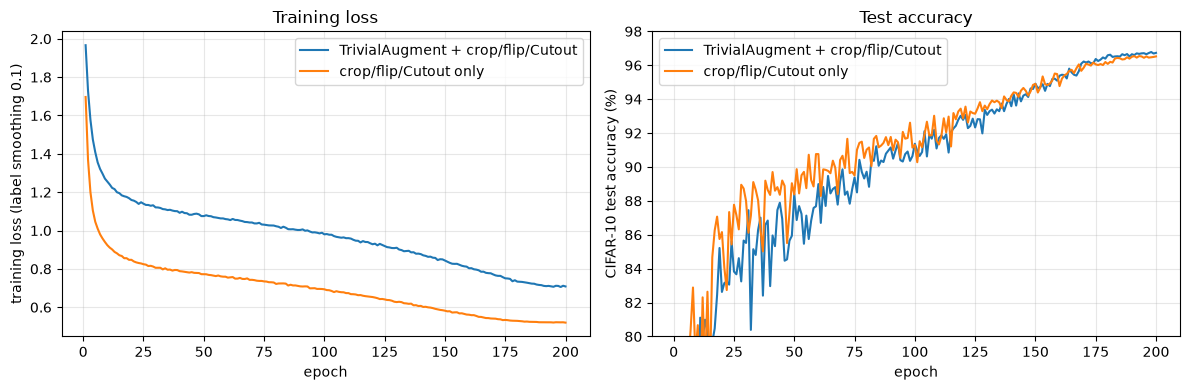

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for run, lab in [('final_B_ta_e200', 'TrivialAugment + crop/flip/Cutout'), ('final_B_base_e200', 'crop/flip/Cutout only')]:
    log = json.loads(Path(f'runs/{run}/log.json').read_text())
    ep = [r['epoch'] for r in log]
    ax[0].plot(ep, [r['train_loss'] for r in log], label=lab)
    ax[1].plot(ep, [100*r['val_acc'] for r in log], label=lab)
ax[0].set(xlabel='epoch', ylabel='training loss (label smoothing 0.1)', title='Training loss')
ax[1].set(xlabel='epoch', ylabel='CIFAR-10 test accuracy (%)', title='Test accuracy', ylim=(80, 98))
for x in ax: x.grid(alpha=0.3); x.legend()
plt.tight_layout(); plt.savefig('figures/curves.png', dpi=160); plt.show()

## Distillation and CutMix (accuracy against the fraction of each run's schedule)

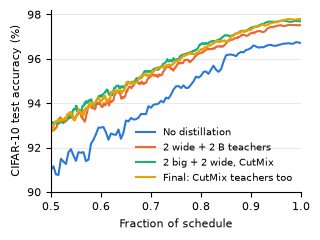

In [5]:
import runpy
runpy.run_path('make_figures.py')
plt.show()

## All experiments

In [6]:
rows = []
for s in sorted(Path('runs').glob('*/summary.json')):
    d = json.loads(s.read_text())
    rows.append((d['name'], d['params'], d['channels'], d['blocks'], d['epochs'], d['args'].get('cutmix', 0),
                 100*d['cifar10_test_acc'], 100*d['cifar10_test_acc_flipTTA'], d['minutes']))
print(f"{'run':20s} {'params':>10s} {'channels':16s} {'blocks':10s} {'ep':>4s} {'CM':>5s} {'test':>7s} {'+TTA':>7s} {'min':>5s}")
for r in rows:
    print(f'{r[0]:20s} {r[1]:>10,} {str(r[2]):16s} {str(r[3]):10s} {r[4]:>4d} {r[5]:>5} {r[6]:6.2f}% {r[7]:6.2f}% {r[8]:5.1f}')

run                      params channels         blocks       ep    CM    test    +TTA   min
big_t1               36,690,090 [160, 320, 640]  [4, 4, 4]   300   0.0  97.66%  97.86%  73.1
big_t2               36,690,090 [160, 320, 640]  [4, 4, 4]   300   0.0  97.67%  97.92%  73.5
big_t3               36,690,090 [160, 320, 640]  [4, 4, 4]   400     1  97.66%  97.83%  98.1
big_t4               36,690,090 [160, 320, 640]  [4, 4, 4]   400     1  97.85%  97.99%  98.3
e50_B_base            4,781,374 [84, 168, 336]   [2, 2, 2]    50     0  95.41%  95.68%   7.2
e50_B_ta              4,781,374 [84, 168, 336]   [2, 2, 2]    50     0  94.80%  95.18%   7.2
final_B_base_e200     4,781,374 [84, 168, 336]   [2, 2, 2]   200     0  96.52%  96.83%  32.2
final_B_ta_e200       4,781,374 [84, 168, 336]   [2, 2, 2]   200     0  96.73%  97.00%  32.4
kd10_B_e1200_cmT_s3   4,781,374 [84, 168, 336]   [2, 2, 2]  1200   1.0  97.82%  97.89% 304.5
kd2_B_e500            4,781,374 [84, 168, 336]   [2, 2, 2]   500     0

## Per-class accuracy of the final model

airplane     98.40%
automobile   99.00%
bird         97.50%
cat          94.70%
deer         98.60%
dog          96.20%
frog         99.20%
horse        98.50%
ship         98.90%
truck        98.10%


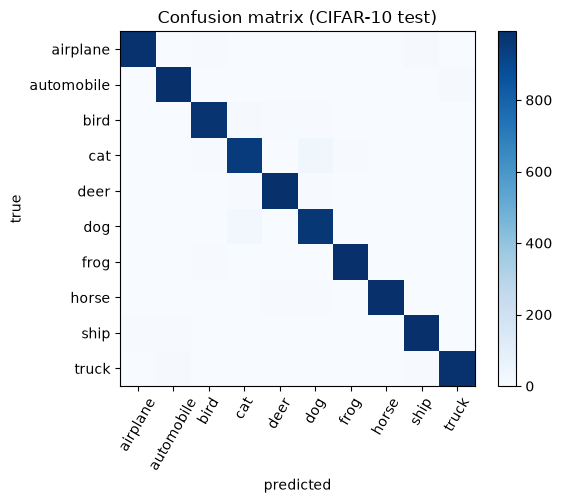

In [7]:
with torch.no_grad():
    from train import normalize
    preds = []
    for k in range(0, 10000, 1000):
        xb = normalize(xte[k:k+1000])
        with torch.autocast('cuda', dtype=torch.bfloat16):
            o = model(xb).float().softmax(1) + model(xb.flip(3)).float().softmax(1)
        preds.append(o.argmax(1))
preds = torch.cat(preds).cpu().numpy(); y = yte.cpu().numpy()
classes = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']
cm = np.zeros((10, 10), int)
for t, p in zip(y, preds): cm[t, p] += 1
for i, c in enumerate(classes): print(f'{c:11s} {100*cm[i,i]/cm[i].sum():6.2f}%')
plt.figure(figsize=(6, 5)); plt.imshow(cm, cmap='Blues'); plt.colorbar()
plt.xticks(range(10), classes, rotation=60); plt.yticks(range(10), classes)
plt.xlabel('predicted'); plt.ylabel('true'); plt.title('Confusion matrix (CIFAR-10 test)')
plt.tight_layout(); plt.savefig('figures/confusion.png', dpi=160); plt.show()

## Kaggle submission (2,000 held-out images, labels hidden)
Public scores of every upload, copied from the competition's Submissions page. The public score uses about half of the images. The last 4 rows are test-time ideas that I tried and did not use (`predict.py --shifts`, `test_time_checks.py`).

In [8]:
scores = [('final_B_ta_e200', 0.884), ('kd_B_e300', 0.885), ('kd3_B_e800', 0.887), ('kd5_B_e800_cm', 0.895),
          ('kd7_B_e1200_cm05_s1', 0.890), ('kd6_B_e1200_cm1', 0.903), ('kd8_B_e1200_cmT', 0.907), (FINAL, 0.907),
          (FINAL + '_shift9', 0.902), (FINAL + '_shift5', 0.903), ('kd8_B_e1200_cmT_shift9', 0.902), (FINAL + '_bal', 0.895)]
for name, score in scores: print(f'{name:35s} {score:.3f}')

final_B_ta_e200                     0.884
kd_B_e300                           0.885
kd3_B_e800                          0.887
kd5_B_e800_cm                       0.895
kd7_B_e1200_cm05_s1                 0.890
kd6_B_e1200_cm1                     0.903
kd8_B_e1200_cmT                     0.907
kd10_B_e1200_cmT_s3                 0.907
kd10_B_e1200_cmT_s3_shift9          0.902
kd10_B_e1200_cmT_s3_shift5          0.903
kd8_B_e1200_cmT_shift9              0.902
kd10_B_e1200_cmT_s3_bal             0.895


In [9]:
import subprocess, sys
print(subprocess.run([sys.executable, 'predict.py', '--run', FINAL], capture_output=True, text=True).stdout)
sub = list(csv.DictReader(open(f'submissions/{FINAL}.csv')))
print(len(sub), 'rows; first rows:', sub[:3])

model kd10_B_e1200_cmT_s3: 4,781,374 trainable parameters
wrote D:\Files\NYU\Simestirs\Simestr 4 Fall 2026\Deep Learning\Project1\submissions\kd10_B_e1200_cmT_s3.csv | 2000 rows | predicted class counts: [179, 219, 211, 213, 194, 207, 179, 200, 201, 197]

2000 rows; first rows: [{'id': '0', 'label': '6'}, {'id': '1', 'label': '3'}, {'id': '2', 'label': '3'}]
